<a href="https://colab.research.google.com/github/kuroshkarimi/Machine-Learning-and-Data-Analysis/blob/main/Classic_Machine_Learning/Probability_Calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability Calibration

Create a dataset with 20-000 total sample; out of these samples, 40% should be positive and the rest negative. Then train a small neural network, inspect its scores, and check if the probabilities are calibrated.

For generation of the data use 'make_classification()' function from sickit learn data package with the following characteristics:

| Parameter | Definition|
|---|---|
| `n_samples=20_000` | Generate 20,000 observations. The underscore makes the number easier to read; `20_000` equals `20000`. |
| `n_features=20` | Give each observation 20 numerical features. |
| `n_informative=10` | Use 10 original features to construct patterns that distinguish the classes. |
| `n_redundant=5` | Add 5 features created as random linear combinations of the informative features. |
| `weights=[0.98, 0.02]` | Assign 98% of samples to class `0` and 2% to class `1`. |
| `flip_y=0` | Disable random reassignment of class labels. |
| `random_state=42` | Fix the random seed so the same call is reproducible in the same software environment. |




In [46]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

SEED = 42

# 1. Generate features and actual labels.
x, y = make_classification(
    n_samples=20_000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    weights=[0.6, 0.4],
    flip_y=0,
    random_state=SEED
)

# 2. Reserve 20% for final evaluation.
x_remaining, x_test, y_remaining, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# 3. Split the remainder into training and calibration data.
# Overall: 60% training, 20% calibration, 20% testing.
x_train, x_cal, y_train, y_cal = train_test_split(
    x_remaining,
    y_remaining,
    test_size=0.25,
    stratify=y_remaining,
    random_state=SEED
)

# 4. Train a model without applying probability calibration.
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=10,
    random_state=SEED
)

model.fit(x_train, y_train)

p_cal_uncalibrated = model.predict_proba(x_cal)[:, 1]
p_test_uncalibrated = model.predict_proba(x_test)[:, 1]

          bin  count  positives  mean_probability  positive_fraction       gap                 assessment
(-0.001, 0.1]   1330         66          0.029100           0.049624 -0.020524 Within 5 percentage points
   (0.1, 0.2]    400         55          0.129845           0.137500 -0.007655 Within 5 percentage points
   (0.2, 0.3]    629        156          0.239035           0.248013 -0.008978 Within 5 percentage points
   (0.3, 0.4]      9          3          0.322581           0.333333 -0.010753 Within 5 percentage points
   (0.5, 0.6]     10          8          0.577409           0.800000 -0.222591             Underestimated
   (0.6, 0.7]    105         67          0.659860           0.638095  0.021765 Within 5 percentage points
   (0.7, 0.8]    642        440          0.710754           0.685358  0.025396 Within 5 percentage points
   (0.8, 0.9]     20         16          0.866213           0.800000  0.066213              Overestimated
   (0.9, 1.0]    855        789          0.934

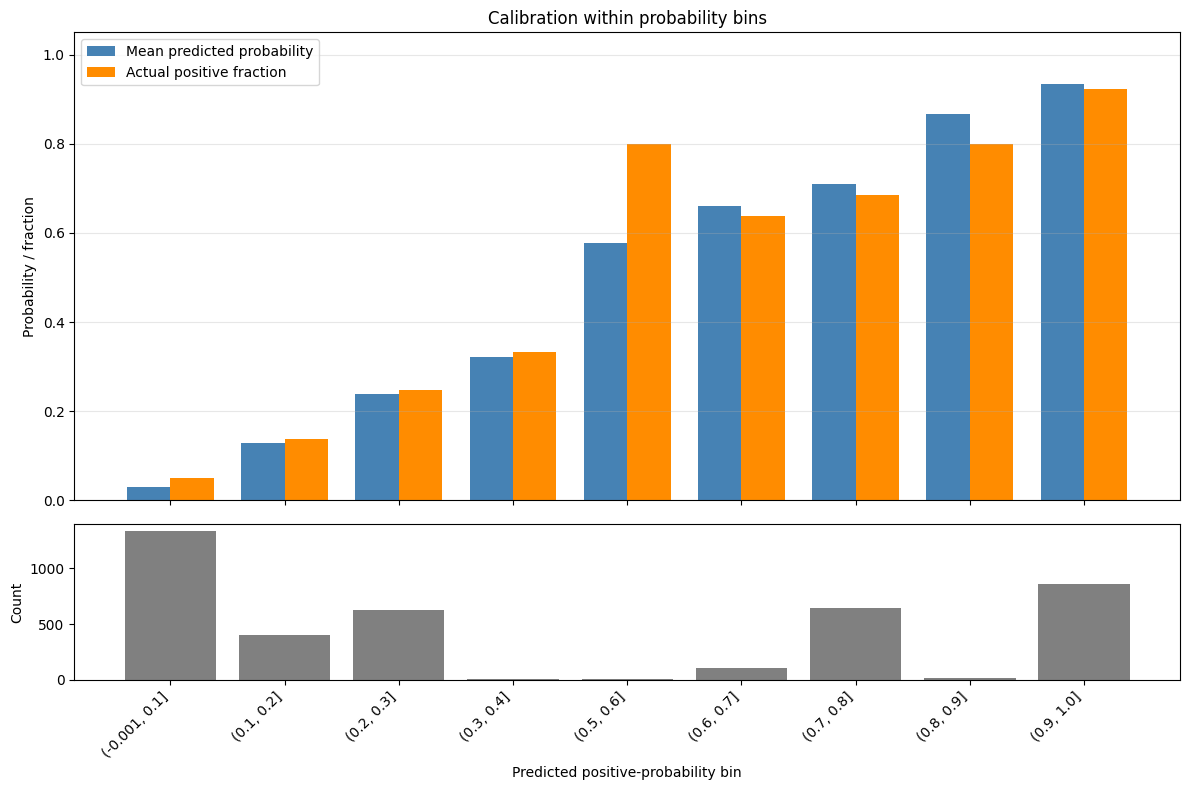

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actual labels: 0 = negative, 1 = positive
# Scores: predicted probability of the POSITIVE class
y_true = np.asarray(y_test).ravel()
probabilities = np.asarray(p_test_uncalibrated).ravel()

data = pd.DataFrame({
    "actual": y_true,
    "probability": probabilities,
})

# Ten equal-width bins: [0, 0.1], (0.1, 0.2], ..., (0.9, 1.0]
bin_edges = np.linspace(0, 1, 11)

data["bin"] = pd.cut(
    data["probability"],
    bins=bin_edges,
    include_lowest=True,
)

summary = (
    data.groupby("bin", observed=False)
    .agg(
        count=("actual", "size"),
        positives=("actual", "sum"),
        mean_probability=("probability", "mean"),
        positive_fraction=("actual", "mean"),
    )
    .reset_index()
)

# Empty bins cannot be assessed.
summary = summary.loc[summary["count"] > 0].copy()

# Positive gap: estimated positive probability is too high.
summary["gap"] = (
    summary["mean_probability"]
    - summary["positive_fraction"]
)

# A descriptive tolerance, not a statistical significance test.
tolerance = 0.05

summary["assessment"] = np.select(
    [
        summary["gap"] > tolerance,
        summary["gap"] < -tolerance,
    ],
    [
        "Overestimated",
        "Underestimated",
    ],
    default="Within 5 percentage points",
)

print(summary.to_string(index=False))

positions = np.arange(len(summary))
width = 0.38

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0].bar(
    positions - width / 2,
    summary["mean_probability"],
    width,
    label="Mean predicted probability",
    color="steelblue",
)

axes[0].bar(
    positions + width / 2,
    summary["positive_fraction"],
    width,
    label="Actual positive fraction",
    color="darkorange",
)

axes[0].set_ylabel("Probability / fraction")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Calibration within probability bins")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    positions,
    summary["count"],
    color="gray",
)

axes[1].set_ylabel("Count")
axes[1].set_xlabel("Predicted positive-probability bin")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(
    summary["bin"].astype(str),
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

In [39]:
print('validation average precision:',
      average_precision_score(y_val, val_scores))


validation average precision: 0.998183395430396
